# 1. Introdução

**Projeto:** alerta precoce de onboardings abandonados em uma empresa de *employer of record* (EOR).

**Pergunta de negócio.** Dado um onboarding ainda aberto no dia 3, 7 ou 14 depois de criado, qual é a chance de ele terminar **perdido (`lost`)** em vez de **concluído (`completed`)**? Se a equipe de Customer Success souber disso cedo, ainda consegue agir: ligar para o candidato, cobrar o cliente, corrigir um erro administrativo.

**Valor.** Cerca de 18 a 19% dos onboardings com desfecho terminam perdidos. Cada perda é uma contratação que nunca começa: receita não realizada e esforço comercial e operacional desperdiçado.

**Fase CRISP-DM.** Este caderno cobre *Entendimento do negócio* (resumo), *Entendimento dos dados* e *Preparação dos dados* (limpeza, rótulo, base final e dicionário). A modelagem, a avaliação e a implantação estão no caderno `2_modelagem_onboarding.ipynb`.

**Dados.** Extrações somente de leitura do banco Dev (nunca PROD), já salvas em `data/input/`. Nenhum acesso a banco é necessário para executar este caderno. Não há nomes de pessoas nem valores salariais nas bases.

# 2. Importação das bibliotecas

Pandas e NumPy para os dados; Matplotlib e Seaborn para os gráficos (paleta *colorblind*, legível para daltônicos).

In [1]:
from pathlib import Path
import sys, warnings, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore")
ROOT = Path("..").resolve()                 # pasta submission/ (os notebooks ficam em submission/notebooks)
INPUT, FINAL, MODELS, REPORTS = ROOT / "data" / "input", ROOT / "data" / "final", ROOT / "models", ROOT / "reports"
sys.path.insert(0, str(ROOT / "src"))       # features.py, model_utils.py, role_features.py (copias do projeto)

sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12, "axes.labelsize": 10})
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
print("pasta do pacote:", ROOT)

pasta do pacote: /Users/filipesilva/Documents/datascience/onboarding_early_warning/submission


# 3. Carregamento dos dados

Cinco arquivos em `data/input/` (copiados do projeto; os originais permanecem intactos):

| Arquivo | Conteúdo | Origem (SQL em `sql/`) |
|---|---|---|
| `onboardings_base.csv` | um registro por onboarding: desfecho, datas e marcos do funcionário | `extract_onboardings.sql` |
| `onboardings_events.csv` | tarefas concluídas, falhas e documentos até o dia 3, 7 e 14 | `extract_events.sql` |
| `onboardings_events_v2.csv` | tarefas concluídas por tipo, última atividade e ritmo | `extract_events_v2.sql` |
| `onboardings_day0.csv` | atributos do emprego, contrato, vaga e oferta na criação | `extract_day0.sql` |
| `onboarding_labels.csv` | conjunto rotulado (concluído ou perdido) com as regras da seção 8 | `build_labels.py` |

In [2]:
base = pd.read_csv(INPUT / "onboardings_base.csv", low_memory=False)
events = pd.read_csv(INPUT / "onboardings_events.csv", low_memory=False)
events_v2 = pd.read_csv(INPUT / "onboardings_events_v2.csv", low_memory=False)
day0 = pd.read_csv(INPUT / "onboardings_day0.csv", low_memory=False)
labels = pd.read_csv(INPUT / "onboarding_labels.csv", low_memory=False)

resumo = pd.DataFrame({"linhas": [len(d) for d in (base, events, events_v2, day0, labels)],
                       "colunas": [d.shape[1] for d in (base, events, events_v2, day0, labels)]},
                      index=["base", "events", "events_v2", "day0", "labels"])
display(resumo)

,linhas,colunas
base,27975,24
events,27975,16
events_v2,20876,70
day0,27975,32
labels,19855,43


**Extração opcional (desligada).** As extrações foram produzidas com o SQL de `sql/` contra o banco Dev, pela ferramenta de linha de comando `dbv` (somente leitura, nunca PROD). A célula abaixo **não** é necessária: serve apenas para documentar como refazer a extração em um computador com acesso ao Dev. Ela fica desligada (`RUN_DB_EXTRACT = False`) para que o caderno rode sozinho.

In [3]:
RUN_DB_EXTRACT = False   # mantenha False: o pacote ja traz as extracoes em data/input/

if RUN_DB_EXTRACT:
    import subprocess
    DBV = "/Users/filipesilva/dev/dbeaver-cli/dbv"          # ferramenta local; requer acesso ao banco Dev
    for nome, sql in [("onboardings_base", "extract_onboardings.sql"), ("onboardings_events", "extract_events.sql"),
                      ("onboardings_events_v2", "extract_events_v2.sql"), ("onboardings_day0", "extract_day0.sql")]:
        r = subprocess.run([DBV, "query", "velocity", "-f", str(ROOT / "sql" / sql), "--db", "velocity", "--format", "csv",
                            "--limit", "0", "-o", str(ROOT / "data" / "live" / f"{nome}.csv")], capture_output=True, text=True)
        print(nome, "ok" if r.returncode == 0 else r.stderr[-200:])
else:
    print("Extracao desligada. SQL disponivel em:", sorted(p.name for p in (ROOT / "sql").glob("*.sql")))

Extracao desligada. SQL disponivel em: ['extract_day0.sql', 'extract_events.sql', 'extract_events_v2.sql', 'extract_onboardings.sql']


# 4. Conhecendo a base

Dimensão, colunas, tipos, valores únicos e memória da base principal (`base`).

In [4]:
print("dimensao da base:", base.shape)
estrutura = pd.DataFrame({"tipo": base.dtypes.astype(str), "valores_unicos": base.nunique(), "pct_vazios": base.isna().mean().mul(100).round(1)})
display(estrutura)
print(f"memoria: {base.memory_usage(deep=True).sum() / 1e6:.1f} MB")

dimensao da base: (27975, 24)


,tipo,valores_unicos,pct_vazios
onboarding_id,int64,27975,0.000
employment_id,int64,27969,0.000
employment_uid,object,27969,0.000
client_uid,object,3527,0.000
employee_id,int64,26902,0.000
process_id,int64,27975,0.000
created_at,object,27834,0.000
status,object,5,0.000
lost_reason,object,38,84.900
lost_date,object,1852,84.500


memoria: 34.2 MB


# 5. Valores ausentes, duplicados e estatísticas descritivas

Os vazios nos marcos do funcionário (`ee_first_logged_in_at`, `ee_info_*`, `offer_finalized_at`) **não são erro**: significam que o evento não aconteceu (ou não foi registrado). `lost_date` e `lost_reason` só existem para onboardings perdidos.

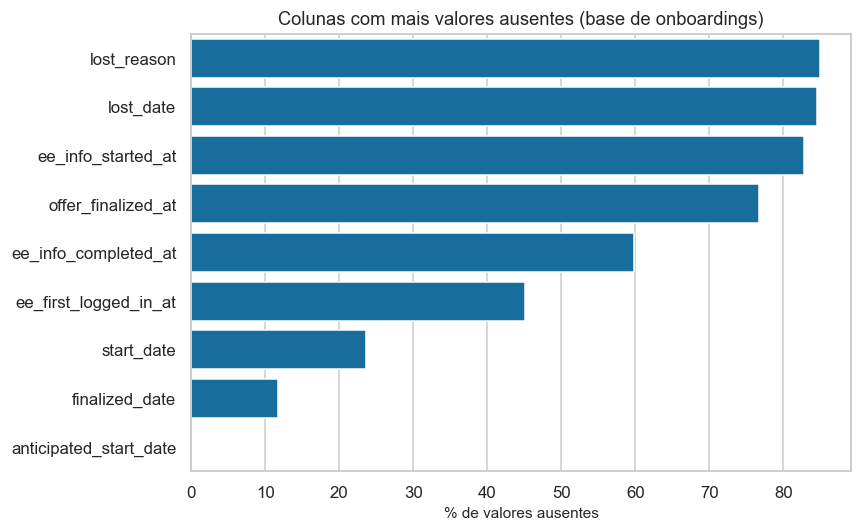

linhas duplicadas (todas as colunas): 0
onboarding_id repetido: 0 | employment_uid repetido: 6


In [5]:
vazios = base.isna().mean().mul(100).sort_values(ascending=False)
top = vazios[vazios > 0].head(15)
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=top.values, y=top.index, ax=ax, color=sns.color_palette("colorblind")[0])
ax.set_xlabel("% de valores ausentes"); ax.set_ylabel(""); ax.set_title("Colunas com mais valores ausentes (base de onboardings)")
plt.tight_layout(); plt.show()

print("linhas duplicadas (todas as colunas):", int(base.duplicated().sum()))
print("onboarding_id repetido:", int(base.onboarding_id.duplicated().sum()), "| employment_uid repetido:", int(base.employment_uid.duplicated().sum()))

In [6]:
numericas = ["employee_id", "process_id"]
display(base[numericas].describe().T)
datas = ["created_at", "start_date", "anticipated_start_date", "lost_date", "finalized_date"]
resumo_datas = pd.DataFrame({c: [pd.to_datetime(base[c], errors="coerce").min(), pd.to_datetime(base[c], errors="coerce").max(), base[c].notna().mean()] for c in datas}, index=["minimo", "maximo", "preenchido"]).T
display(resumo_datas)

,count,mean,std,min,25%,50%,75%,max
employee_id,"27,975.000","18,607.723","9,917.384",3.000,"10,149.500","18,423.000","26,843.500","41,229.000"
process_id,"27,975.000","22,669.213","14,375.779",5.000,"9,058.500","22,193.000","35,644.500","48,813.000"


,minimo,maximo,preenchido
created_at,2020-04-13 21:03:47,2026-11-16 12:23:05,1.000
start_date,1969-12-03 00:00:00,2202-08-08 00:00:00,0.763
anticipated_start_date,1969-12-02 00:00:00,2029-05-18 00:00:00,0.998
lost_date,2019-12-25 00:00:00,2026-11-30 00:00:00,0.155
finalized_date,1970-01-08 00:00:00,2026-12-09 00:00:00,0.882


# 6. Análise das variáveis categóricas

Status do onboarding, país, produto (`solution_type`) e motivo de perda.

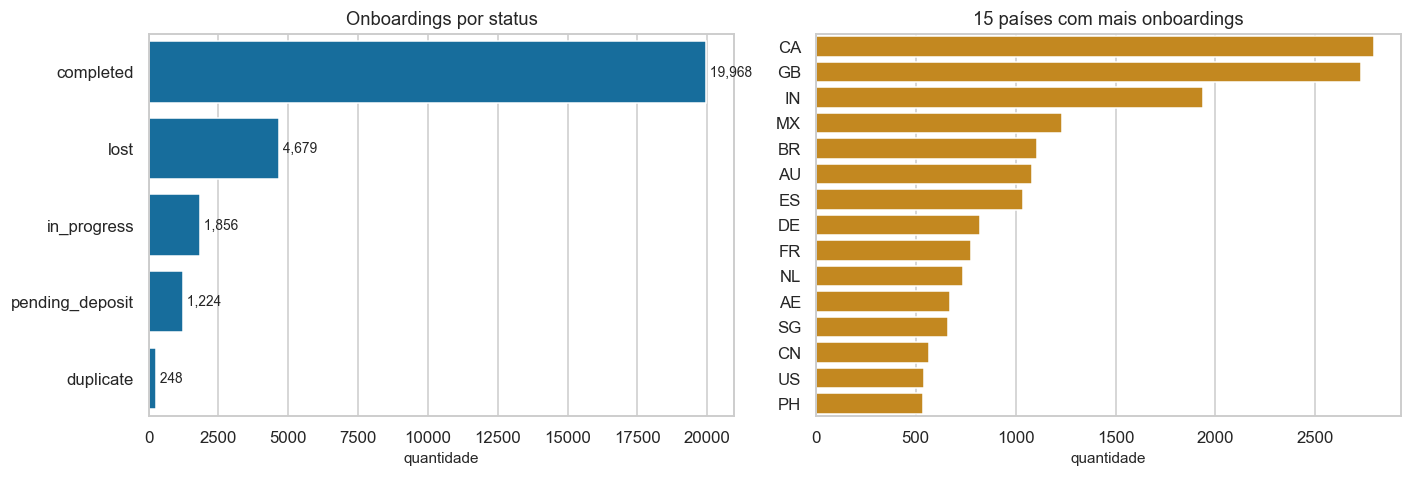

,quantidade,percentual
status,,
completed,19968,71.400
lost,4679,16.700
in_progress,1856,6.600
pending_deposit,1224,4.400
duplicate,248,0.900


,quantidade
solution_type,
Supported Employee,27241
Multi-Country Payroll,636
Contractor Payments,98


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
st = base.status.value_counts()
sns.barplot(x=st.values, y=st.index, ax=axes[0], color=sns.color_palette("colorblind")[0]); axes[0].set_title("Onboardings por status"); axes[0].set_xlabel("quantidade"); axes[0].set_ylabel("")
for i, v in enumerate(st.values): axes[0].text(v, i, f" {v:,}", va="center", fontsize=9)
pais = base.country_code.value_counts().head(15)
sns.barplot(x=pais.values, y=pais.index, ax=axes[1], color=sns.color_palette("colorblind")[1]); axes[1].set_title("15 países com mais onboardings"); axes[1].set_xlabel("quantidade"); axes[1].set_ylabel("")
plt.tight_layout(); plt.show()
display(base.status.value_counts().to_frame("quantidade").assign(percentual=lambda d: (100 * d.quantidade / d.quantidade.sum()).round(1)))
display(base.solution_type.value_counts(dropna=False).to_frame("quantidade"))

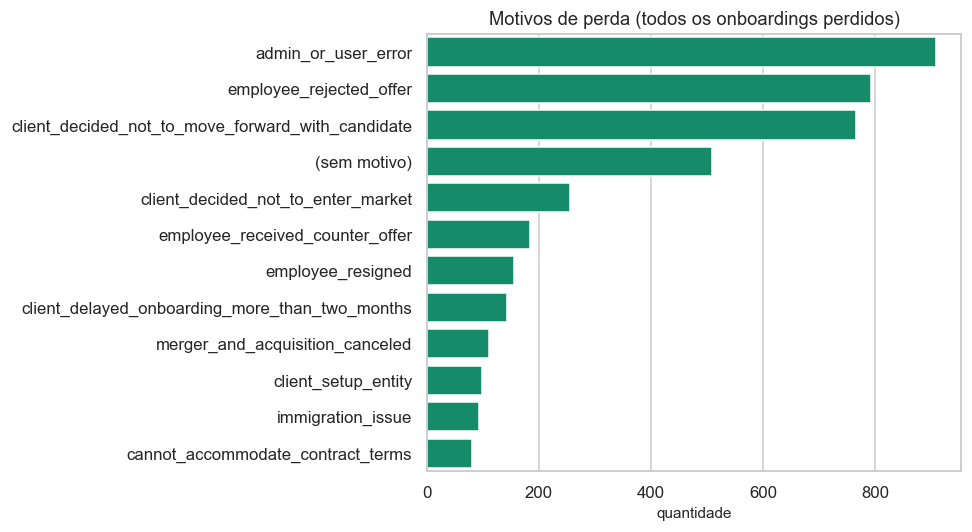

motivos distintos: 38 | perdidos: 4679


In [8]:
motivos = base.loc[base.status == "lost", "lost_reason"].fillna("(sem motivo)").value_counts()
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x=motivos.head(12).values, y=motivos.head(12).index, ax=ax, color=sns.color_palette("colorblind")[2])
ax.set_title("Motivos de perda (todos os onboardings perdidos)"); ax.set_xlabel("quantidade"); ax.set_ylabel("")
plt.tight_layout(); plt.show()
print("motivos distintos:", len(motivos), "| perdidos:", int(motivos.sum()))

# 7. Análise das variáveis numéricas e dos eventos precoces

Aqui já usamos o conjunto rotulado (`labels`, construído na seção 8) para comparar **concluídos** e **perdidos**: tempo até o desfecho e o que já tinha acontecido até o dia 3, 7 e 14. Para cada ponto de checagem só entram onboardings **ainda abertos** naquele dia (`days_to_outcome > d`), que é exatamente a população que a equipe poderia ajudar.

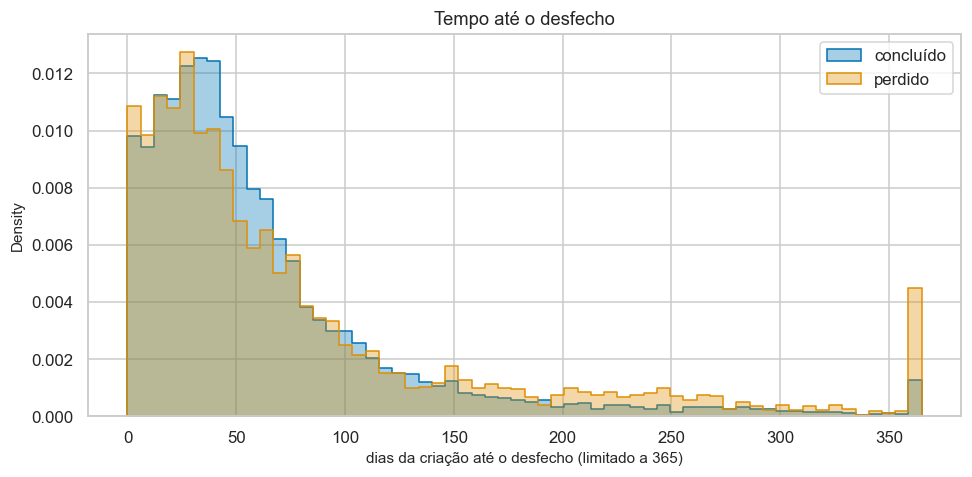

               count   mean     std   min    10%    50%     90%       max
resultado                                                                
concluído 16,193.000 64.000  70.000 0.000 11.000 44.000 132.000 1,289.000
perdido    3,662.000 84.000 117.000 0.000 10.000 47.000 209.000 1,490.000


In [9]:
lab = labels.copy()
lab["resultado"] = lab.status.map({"completed": "concluído", "lost": "perdido"})
fig, ax = plt.subplots(figsize=(9, 4.5))
for r, cor in zip(["concluído", "perdido"], sns.color_palette("colorblind")[:2]):
    sns.histplot(lab.loc[lab.resultado == r, "days_to_outcome"].clip(0, 365), bins=60, stat="density", element="step", fill=True, alpha=0.35, color=cor, label=r, ax=ax)
ax.set_xlabel("dias da criação até o desfecho (limitado a 365)"); ax.set_title("Tempo até o desfecho"); ax.legend()
plt.tight_layout(); plt.show()
print(lab.groupby("resultado").days_to_outcome.describe(percentiles=[.1, .5, .9]).round(0))

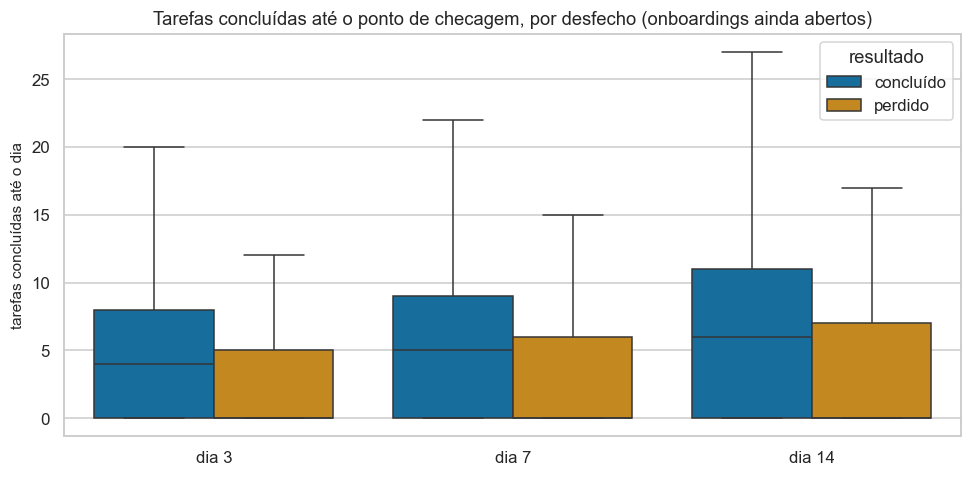

                  count  mean  median
dia    resultado                     
dia 14 concluído  13945 6.330   6.000
       perdido     3114 3.520   0.000
dia 3  concluído  15676 4.570   4.000
       perdido     3522 2.660   0.000
dia 7  concluído  15097 5.230   5.000
       perdido     3394 3.010   0.000


In [10]:
linhas = []
for d in (3, 7, 14):
    aberto = lab[lab.days_to_outcome > d]
    for r in ("concluído", "perdido"):
        x = aberto[aberto.resultado == r]
        linhas.append({"dia": d, "resultado": r, "tarefas_concluidas": x[f"done_d{d}"].to_numpy(), "n": len(x)})
tab = pd.concat([pd.DataFrame({"dia": l["dia"], "resultado": l["resultado"], "tarefas concluídas até o dia": l["tarefas_concluidas"]}) for l in linhas])
tab["dia"] = "dia " + tab.dia.astype(str)
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.boxplot(data=tab, x="dia", y="tarefas concluídas até o dia", hue="resultado", ax=ax, showfliers=False)
ax.set_title("Tarefas concluídas até o ponto de checagem, por desfecho (onboardings ainda abertos)"); ax.set_xlabel("")
plt.tight_layout(); plt.show()
print(tab.groupby(["dia", "resultado"])["tarefas concluídas até o dia"].agg(["count", "mean", "median"]).round(2))

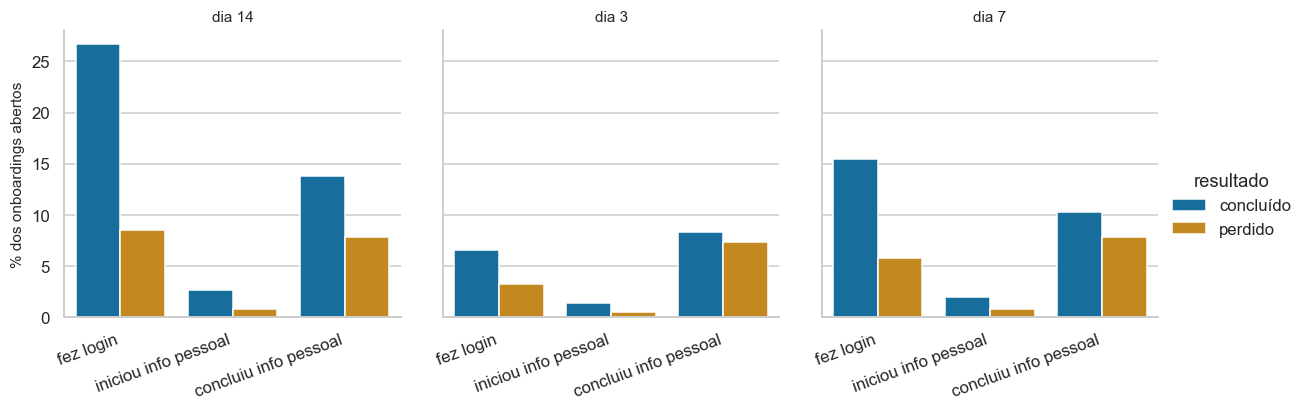

resultado                     concluído  perdido
dia    marco                                    
dia 14 concluiu info pessoal     13.800    7.800
       fez login                 26.700    8.500
       iniciou info pessoal       2.600    0.800
dia 3  concluiu info pessoal      8.300    7.300
       fez login                  6.600    3.200
       iniciou info pessoal       1.400    0.500
dia 7  concluiu info pessoal     10.300    7.800
       fez login                 15.500    5.800
       iniciou info pessoal       2.000    0.800

In [11]:
def marcos_ate(d):
    a = lab[lab.days_to_outcome > d].copy()
    for c in ["created_at", "ee_first_logged_in_at", "ee_info_started_at", "ee_info_completed_at"]:
        a[c] = pd.to_datetime(a[c], errors="coerce")
    corte = a.created_at + pd.Timedelta(days=d)
    return pd.DataFrame({"dia": f"dia {d}", "resultado": a.resultado,
                         "fez login": (a.ee_first_logged_in_at <= corte), "iniciou info pessoal": (a.ee_info_started_at <= corte),
                         "concluiu info pessoal": (a.ee_info_completed_at <= corte)})
m = pd.concat([marcos_ate(d) for d in (3, 7, 14)])
resumo_marcos = m.groupby(["dia", "resultado"]).mean(numeric_only=True).mul(100).round(1).reset_index().melt(id_vars=["dia", "resultado"], var_name="marco", value_name="% que já aconteceu")
g = sns.catplot(data=resumo_marcos, x="marco", y="% que já aconteceu", hue="resultado", col="dia", kind="bar", height=3.6, aspect=1.0)
g.set_xticklabels(rotation=20, ha="right"); g.set_titles("{col_name}"); g.set_axis_labels("", "% dos onboardings abertos")
plt.show()
display(resumo_marcos.pivot_table(index=["dia", "marco"], columns="resultado", values="% que já aconteceu"))

# 8. Problemas de qualidade encontrados e como cada um foi tratado

O quadro abaixo reconstrói, a partir de `onboardings_base.csv`, o funil que leva de **27.975** onboardings até o conjunto rotulado de **19.855**. As regras seguem o que foi decidido nas fases anteriores:

1. só entram onboardings **concluídos ou perdidos** (os `in_progress`, `pending_deposit` e `duplicate` não têm desfecho);
2. fora os empregos marcados como duplicados (*dedup*);
3. fora os **dias de carga em massa** (2021-12-07, 2021-12-08 e 2022-03-03): são importações, não onboardings reais;
4. só onboardings criados **há pelo menos 180 dias** da data dos dados (desfechos tardios ainda podem aparecer nos mais jovens);
5. fora os que têm **desfecho datado antes da criação** do registro (o registro foi criado depois do evento real: não existe alerta precoce possível).

,etapa,onboardings,removidos
0,Todos os onboardings,27975,0
1,Concluídos ou perdidos,24647,3328
2,Sem emprego marcado como duplicado,24603,44
3,Sem os dias de carga em massa,23492,1111
4,Criados há 180 dias ou mais,22194,1298
5,Sem desfecho anterior à criação (conjunto rotu...,19855,2339


OK: funil confere com a documentação: [27975, 24647, 24603, 23492, 22194, 19855]


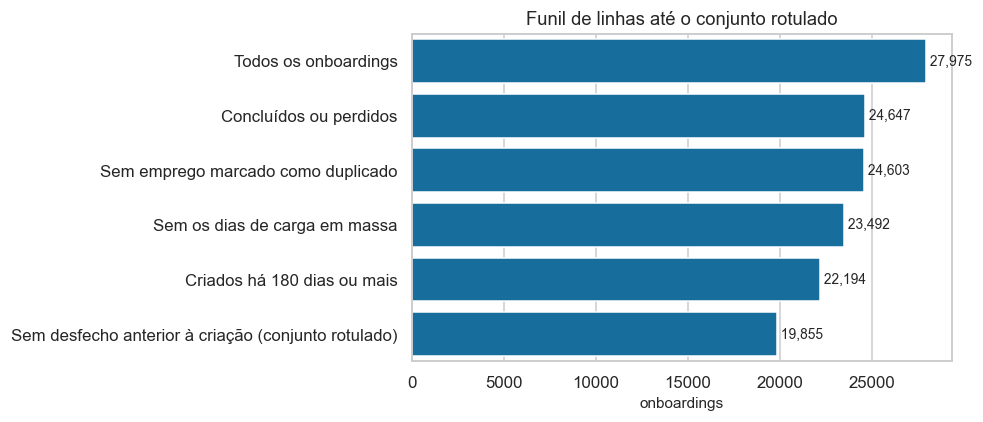

In [12]:
A = base.copy()
for c in ["created_at", "ee_first_logged_in_at", "ee_info_started_at", "ee_info_completed_at", "offer_finalized_at"]:
    A[c] = pd.to_datetime(A[c], utc=True, errors="coerce").dt.tz_localize(None)
for c in ["lost_date", "finalized_date"]:
    A[c] = pd.to_datetime(A[c], errors="coerce")
DATA_REF = pd.to_datetime(A.data_date.iloc[0])
dia_criacao = A.created_at.dt.normalize()
A["outcome_date"] = A.lost_date.where(A.status == "lost").fillna(A.finalized_date)
A["days_to_outcome"] = (A.outcome_date - dia_criacao).dt.days

funil = [("Todos os onboardings", len(A))]
B = A[A.status.isin(["completed", "lost"])];                         funil.append(("Concluídos ou perdidos", len(B)))
B = B[~B.is_dedup];                                                   funil.append(("Sem emprego marcado como duplicado", len(B)))
dia_carga = B.created_at.dt.date.astype(str).isin(["2021-12-07", "2021-12-08", "2022-03-03"]); B = B[~dia_carga]
funil.append(("Sem os dias de carga em massa", len(B)))
B = B[dia_criacao.loc[B.index] <= DATA_REF - pd.Timedelta(days=180)]; funil.append(("Criados há 180 dias ou mais", len(B)))
fora = B.days_to_outcome < 0; B_antes = B.copy(); B = B[~fora];       funil.append(("Sem desfecho anterior à criação (conjunto rotulado)", len(B)))

funil = pd.DataFrame(funil, columns=["etapa", "onboardings"]); funil["removidos"] = (-funil.onboardings.diff()).fillna(0).astype(int)
display(funil)
esperado = [27975, 24647, 24603, 23492, 22194, 19855]
assert funil.onboardings.tolist() == esperado, funil.onboardings.tolist()
print("OK: funil confere com a documentação:", esperado)

fig, ax = plt.subplots(figsize=(9, 4))
sns.barplot(data=funil, y="etapa", x="onboardings", ax=ax, color=sns.color_palette("colorblind")[0])
for i, v in enumerate(funil.onboardings): ax.text(v, i, f" {v:,}", va="center", fontsize=9)
ax.set_title("Funil de linhas até o conjunto rotulado"); ax.set_xlabel("onboardings"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

In [13]:
fora_status = base.status.value_counts().drop(["completed", "lost"], errors="ignore")
print("Status sem desfecho (removidos na etapa 1):", fora_status.to_dict())
print("Empregos duplicados removidos (etapa 2):", int(funil.removidos[2]))
print("Linhas de carga em massa removidas (etapa 3):", int(funil.removidos[3]), "| por data:", A[A.created_at.dt.date.astype(str).isin(['2021-12-07','2021-12-08','2022-03-03'])].created_at.dt.date.astype(str).value_counts().to_dict())
print("Criados há menos de 180 dias (etapa 4):", int(funil.removidos[4]))
print("Desfecho antes da criação (etapa 5):", int(funil.removidos[5]))

# desfecho antes da criação: quem são? (proporção por desfecho e por ano de criação, antes de remover)
x = B_antes.assign(antes=lambda d: d.days_to_outcome < 0, ano=lambda d: d.created_at.dt.year)
print("\nproporção com desfecho antes da criação, por desfecho:", x.groupby("status").antes.mean().round(3).to_dict())
print("por ano de criação:", x.groupby("ano").antes.mean().round(3).to_dict())

# marcos do funcionário datados antes da criação (viram vazio: evento desconhecido)
for c in ["ee_first_logged_in_at", "ee_info_started_at", "ee_info_completed_at", "offer_finalized_at"]:
    n = int((B[c].notna() & (B[c] < B.created_at)).sum())
    print(f"{c}: {n} valores anteriores à criação (viram vazio)")

Status sem desfecho (removidos na etapa 1): {'in_progress': 1856, 'pending_deposit': 1224, 'duplicate': 248}
Empregos duplicados removidos (etapa 2): 44
Linhas de carga em massa removidas (etapa 3): 1111 | por data: {'2021-12-08': 514, '2021-12-07': 389, '2022-03-03': 208}
Criados há menos de 180 dias (etapa 4): 1298
Desfecho antes da criação (etapa 5): 2339

proporção com desfecho antes da criação, por desfecho: {'completed': 0.099, 'lost': 0.134}
por ano de criação: {2020: 0.03, 2021: 0.093, 2022: 0.08, 2023: 0.098, 2024: 0.11, 2025: 0.137, 2026: 0.182}
ee_first_logged_in_at: 558 valores anteriores à criação (viram vazio)
ee_info_started_at: 0 valores anteriores à criação (viram vazio)
ee_info_completed_at: 7 valores anteriores à criação (viram vazio)
offer_finalized_at: 0 valores anteriores à criação (viram vazio)


**Resumo do tratamento.**

| Problema | Quantidade | Tratamento |
|---|---:|---|
| Status sem desfecho (`in_progress`, `pending_deposit`, `duplicate`) | 3.328 | fora do rótulo; `pending_deposit` é uma etapa de 2026 que os modelos não viram |
| Empregos marcados como duplicados | 44 | removidos |
| Dias de carga em massa (2021-12-07/08, 2022-03-03) | 1.111 | removidos |
| Criados há menos de 180 dias | 1.298 | removidos (desfecho ainda pode mudar) |
| Desfecho anterior à criação do registro | 2.339 | removidos (sem alerta precoce possível) |
| Primeiro login anterior à criação | 558 | valor vira vazio (evento desconhecido) |
| Conclusão da informação pessoal anterior à criação | 7 | valor vira vazio |

# 9. O rótulo e sua regra

* `y_lost = 1` quando o onboarding terminou **perdido**; `y_lost = 0` quando terminou **concluído**.
* Todo motivo de perda conta como perda (a análise por motivo é feita no caderno 2).
* O desfecho tem data: `lost_date` (perdidos; se faltar, usa-se `finalized_date`) ou `finalized_date` (concluídos). `days_to_outcome` é a diferença em dias para a data de criação.

rotulados: 19,855 | perdidos: 3,662 (18.4%) | concluídos: 16,193


created_year,2020,2021,2022,2023,2024,2025,2026
onboardings,990.000,"3,198.000","4,686.000","3,374.000","2,835.000","3,193.000","1,579.000"
perdidos,104.000,484.000,843.000,714.000,545.000,592.000,380.000
pct_perdidos,10.500,15.100,18.000,21.200,19.200,18.500,24.100


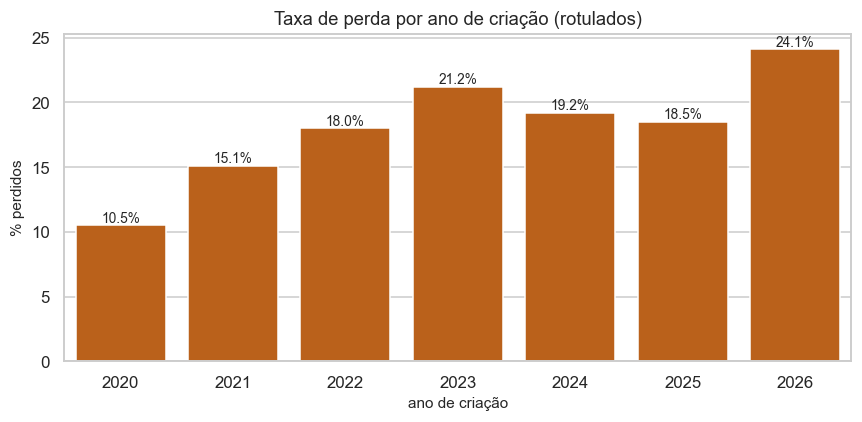

In [14]:
L = B.copy()
L["y_lost"] = (L.status == "lost").astype(int)
L["created_year"] = L.created_at.dt.year

# confere com o arquivo de rótulos usado em todo o projeto
assert set(L.onboarding_id) == set(labels.onboarding_id), "conjunto rotulado difere do arquivo onboarding_labels.csv"
assert int(L.y_lost.sum()) == 3662 and len(L) == 19855
print(f"rotulados: {len(L):,} | perdidos: {int(L.y_lost.sum()):,} ({L.y_lost.mean():.1%}) | concluídos: {int((1 - L.y_lost).sum()):,}")

por_ano = L.groupby("created_year").y_lost.agg(onboardings="size", perdidos="sum", pct_perdidos=lambda s: 100 * s.mean()).round(1)
display(por_ano.T)
fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(x=por_ano.index, y=por_ano.pct_perdidos, ax=ax, color=sns.color_palette("colorblind")[3])
for i, v in enumerate(por_ano.pct_perdidos): ax.text(i, v, f"{v:.1f}%", ha="center", va="bottom", fontsize=9)
ax.set_xlabel("ano de criação"); ax.set_ylabel("% perdidos"); ax.set_title("Taxa de perda por ano de criação (rotulados)")
plt.tight_layout(); plt.show()

In [15]:
motivos = L.loc[L.y_lost == 1, "lost_reason"].fillna("(sem motivo)").value_counts()
display(motivos.head(12).to_frame("perdidos"))
q = L.groupby("y_lost").days_to_outcome.quantile([.1, .5, .9]).unstack().round(0)
q.index = ["concluído", "perdido"]; q.columns = ["p10", "p50", "p90"]
display(q)
assert q.loc["perdido"].tolist() == [10, 47, 209], q.loc["perdido"].tolist()
print("OK: tempo até a perda p10/p50/p90 = 10/47/209 dias")

,perdidos
lost_reason,
employee_rejected_offer,679
client_decided_not_to_move_forward_with_candidate,677
admin_or_user_error,514
(sem motivo),439
client_decided_not_to_enter_market,239
employee_received_counter_offer,145
client_delayed_onboarding_more_than_two_months,139
employee_resigned,116
merger_and_acquisition_canceled,94


,p10,p50,p90
concluído,11.000,44.000,132.000
perdido,10.000,47.000,209.000


OK: tempo até a perda p10/p50/p90 = 10/47/209 dias


# 10. Populações por ponto de checagem

No dia *d* só podem receber alerta os onboardings **ainda abertos**. Com o desfecho conhecido, isso é `days_to_outcome > d`. Há duas leituras:

* **Descritiva** (desde 2022-04-01, quando as tarefas passam a ser completas);
* **Para modelagem** (desde 2023-01-01, quando o login passa a ser registrado de forma consistente), dividida em treino (criados antes de 2025) e teste final (2025 em diante).

In [16]:
linhas = []
for d in (0, 3, 7, 14):
    m = (L.days_to_outcome > d) if d else pd.Series(True, index=L.index)
    if d: m &= L.created_at >= "2022-04-01"
    x = L[m]
    linhas.append({"checagem": f"dia {d}", "onboardings": len(x), "perdidos": int(x.y_lost.sum()), "% perdidos": round(100 * x.y_lost.mean(), 1)})
pop_desc = pd.DataFrame(linhas); display(pop_desc)
assert pop_desc.onboardings.tolist() == [19855, 13799, 13222, 12100] and pop_desc.perdidos.tolist() == [3662, 2687, 2590, 2382]

linhas = []
for d in (0, 3, 7, 14):
    m = (L.days_to_outcome > d) if d else pd.Series(True, index=L.index)
    if d: m &= L.created_at >= "2023-01-01"      # o dia 0 usa todos os anos
    x = L[m]; tr = x[x.created_at < "2025-01-01"]; ho = x[x.created_at >= "2025-01-01"]
    linhas.append({"checagem": f"dia {d}", "total": len(x), "treino (antes de 2025)": len(tr), "teste final (2025 em diante)": len(ho), "% perdidos treino": round(100 * tr.y_lost.mean(), 1), "% perdidos teste": round(100 * ho.y_lost.mean(), 1)})
pop_mod = pd.DataFrame(linhas); display(pop_mod)

,checagem,onboardings,perdidos,% perdidos
0,dia 0,19855,3662,18.400
1,dia 3,13799,2687,19.500
2,dia 7,13222,2590,19.600
3,dia 14,12100,2382,19.700


,checagem,total,treino (antes de 2025),teste final (2025 em diante),% perdidos treino,% perdidos teste
0,dia 0,19855,15083,4772,17.800,20.400
1,dia 3,10511,5992,4519,20.400,20.300
2,dia 7,10044,5745,4299,20.500,20.400
3,dia 14,9145,5298,3847,20.900,20.100


Observação: o ponto de checagem **dia 0** usa todos os anos (a partir de 2020): 19.855 onboardings, 15.083 no treino e 4.772 no teste final. Para os dias 3, 7 e 14 a população de modelagem é 10.511, 10.044 e 9.145 (a tabela acima mostra a divisão em treino e teste); esses números são conferidos no caderno 2.

# 11. Estudo de vazamento e de tempo (ponto central da história)

Antes de modelar foi preciso responder: **o que de fato se sabe no dia do alerta?** Dois achados mudaram o projeto.

**(a) Campos preenchidos durante o onboarding denunciam o desfecho.** Tipo de emprego, frequência de pagamento e tipo de contrato são preenchidos à medida que o onboarding avança. Onboardings que nunca avançam ficam em branco, ou recebem um valor "padrão" (`no_payroll_frequency`). Um modelo que usa esses campos parece ótimo e não serve para alerta precoce.

,campo,vazio (%),% perdidos se vazio,% perdidos se preenchido
0,employment_type,48.300,33.600,4.200
1,contract_type,18.000,55.300,10.400


,onboardings,fração perdida
pay_frequency,,
bi_weekly,137,0.051
monthly,14439,0.088
no_payroll_frequency,2560,0.871
semi_monthly,2657,0.056
weekly,62,0.097


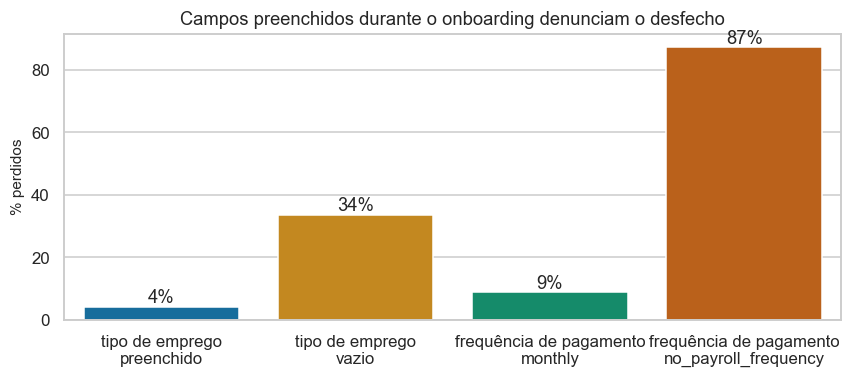

In [17]:
camp = day0[["onboarding_id", "employment_type", "pay_frequency", "contract_type"]].merge(L[["onboarding_id", "y_lost"]], on="onboarding_id")
linhas = []
for c in ["employment_type", "contract_type"]:
    vazio = camp[camp[c].isna()]; cheio = camp[camp[c].notna()]
    linhas.append({"campo": c, "vazio (%)": round(100 * len(vazio) / len(camp), 1), "% perdidos se vazio": round(100 * vazio.y_lost.mean(), 1), "% perdidos se preenchido": round(100 * cheio.y_lost.mean(), 1)})
pf = camp.groupby("pay_frequency").y_lost.agg(["size", "mean"]).round(3)
display(pd.DataFrame(linhas))
display(pf.rename(columns={"size": "onboardings", "mean": "fração perdida"}))
assert round(camp[camp.employment_type.isna()].y_lost.mean(), 2) == 0.34 and round(camp[camp.employment_type.notna()].y_lost.mean(), 2) == 0.04
assert round(pf.loc["no_payroll_frequency", "mean"], 2) == 0.87
fig, ax = plt.subplots(figsize=(8, 3.6))
v = pd.DataFrame({"grupo": ["tipo de emprego\npreenchido", "tipo de emprego\nvazio", "frequência de pagamento\nmonthly", "frequência de pagamento\nno_payroll_frequency"],
                  "% perdidos": [100 * camp[camp.employment_type.notna()].y_lost.mean(), 100 * camp[camp.employment_type.isna()].y_lost.mean(), 100 * pf.loc["monthly", "mean"], 100 * pf.loc["no_payroll_frequency", "mean"]]})
sns.barplot(data=v, x="grupo", y="% perdidos", ax=ax, palette="colorblind")
for i, y in enumerate(v["% perdidos"]): ax.text(i, y, f"{y:.0f}%", ha="center", va="bottom")
ax.set_xlabel(""); ax.set_title("Campos preenchidos durante o onboarding denunciam o desfecho"); plt.tight_layout(); plt.show()

**(b) A maioria dos termos da oferta é escrita depois da criação da oferta.** A auditoria do banco analítico (Snowflake, somente leitura, 25.176 ofertas ligadas a um emprego e criadas a partir de 2023-12, fora dos dias de carga em massa) registra *quando* cada campo foi escrito pela primeira vez (os valores são mascarados, os horários não). Os números abaixo **vêm do relatório dessa auditoria**, documentado em `phases/06_offer_term_timing.md` do projeto; este caderno **não consulta o Snowflake**.

,campo da oferta,% escrito em 1 minuto,% escrito em 1 dia,% escrito depois de 14 dias,% nunca escrito
0,Obrigatoriedade de visto,95.900,97.500,0.500,59.300
1,Salário mensal,37.900,46.400,52.300,18.000
2,Período de experiência (duração),18.600,48.200,47.000,24.500
3,Aviso prévio (duração),15.300,50.100,44.600,51.700
4,Horas semanais,26.300,57.400,37.600,49.000
5,Cláusula de PI,13.900,45.800,49.600,50.300
6,Não concorrência,13.100,57.600,34.100,64.700
7,Participação em aposentadoria (%),1.500,32.900,60.400,82.100
8,Auxílio mensal,10.700,82.500,3.800,67.700
9,Remuneração variável,10.300,82.300,3.700,68.100


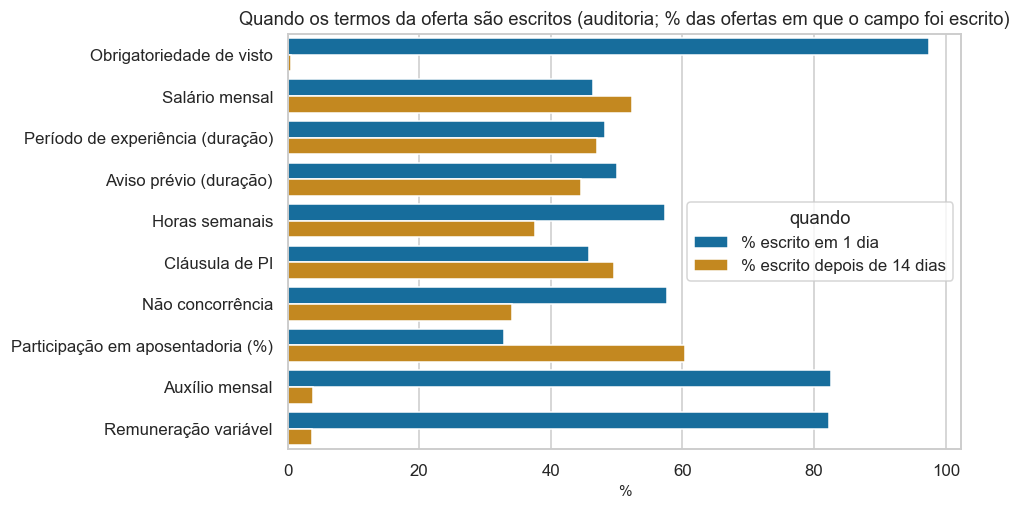

In [18]:
auditoria = pd.DataFrame([
    ("Obrigatoriedade de visto", 95.9, 97.5, 0.5, 59.3), ("Salário mensal", 37.9, 46.4, 52.3, 18.0),
    ("Período de experiência (duração)", 18.6, 48.2, 47.0, 24.5), ("Aviso prévio (duração)", 15.3, 50.1, 44.6, 51.7),
    ("Horas semanais", 26.3, 57.4, 37.6, 49.0), ("Cláusula de PI", 13.9, 45.8, 49.6, 50.3),
    ("Não concorrência", 13.1, 57.6, 34.1, 64.7), ("Participação em aposentadoria (%)", 1.5, 32.9, 60.4, 82.1),
    ("Auxílio mensal", 10.7, 82.5, 3.8, 67.7), ("Remuneração variável", 10.3, 82.3, 3.7, 68.1)],
    columns=["campo da oferta", "% escrito em 1 minuto", "% escrito em 1 dia", "% escrito depois de 14 dias", "% nunca escrito"])
display(auditoria)
fig, ax = plt.subplots(figsize=(9, 4.8))
t = auditoria.melt(id_vars="campo da oferta", value_vars=["% escrito em 1 dia", "% escrito depois de 14 dias"], var_name="quando", value_name="%")
sns.barplot(data=t, y="campo da oferta", x="%", hue="quando", ax=ax)
ax.set_title("Quando os termos da oferta são escritos (auditoria; % das ofertas em que o campo foi escrito)"); ax.set_xlabel("%"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

**Decisão ("plano A").** Nenhum termo de oferta e nenhum dos quatro campos de emprego (`employment_type`, `pay_frequency`, `contract_type`, `contract_salary_present`) entram nos modelos. O resultado honesto está no caderno 2. Também são excluídos: nomes de pessoas, valores salariais, texto livre, datas de desfecho como atributos e documentos (sem sinal).

# 12. Base final e dicionário de dados

A base final tem **um registro por onboarding rotulado** (19.855) e apenas atributos do plano A, calculados por `src/features.py` (o mesmo código usado no treino e na pontuação semanal):

* **dia 0:** país, produto, moeda, mês e dia da semana, antecedência do início planejado, família e senioridade do cargo, histórico do cliente (onboardings anteriores já resolvidos, taxa de perda suavizada, atividade nos últimos 90 dias) e histórico do funcionário;
* **dias 3, 7 e 14:** marcos do funcionário (login, informação pessoal), tarefas existentes, concluídas e com falha, tarefas concluídas por tipo (assinatura do contrato, documentos, dados do funcionário, depósito, verificação de pagamento, formulários...), dia da última tarefa concluída, dias sem atividade e ritmo recente.

Vazios continuam vazios (sem preenchimento e sem colunas indicadoras). Divisão: `split_final` = `train` (criados antes de 2025-01-01) ou `holdout` (2025 em diante); `fold` = grupo de validação cruzada **por cliente** (só para o treino; -1 no holdout).

In [19]:
import features as FE   # src/features.py (cópia do projeto)

taxa_perda_treino = float(L[L.created_at < "2025-01-01"].y_lost.mean())     # constante de suavização do histórico do cliente
M = FE.build(base, events, events_v2, day0, prior_lost_rate=taxa_perda_treino)
print("recursos construídos para todos os onboardings:", M.shape, "| taxa de perda do treino (suavização):", round(taxa_perda_treino, 5))

feat_cols = list(dict.fromkeys(FE.DAY0 + sum([FE.event_cols(d) for d in (3, 7, 14)], [])))
meta = L[["onboarding_id", "days_to_outcome", "y_lost"]]
F = (M[["onboarding_id", "employment_uid", "client_uid", "created_at", "status", "lost_reason"] + feat_cols]
     .merge(meta, on="onboarding_id", how="inner"))
F["split_final"] = np.where(F.created_at < "2025-01-01", "train", "holdout")

def dobrar_por_cliente(df, k=5):
    tam = df.groupby("client_uid").size().sort_values(ascending=False); soma = np.zeros(k); atrib = {}
    for cli, n in tam.items():
        j = int(soma.argmin()); atrib[cli] = j; soma[j] += n
    return df.client_uid.map(atrib)
tr = F.split_final == "train"
F["fold"] = -1; F.loc[tr, "fold"] = dobrar_por_cliente(F[tr]).to_numpy()

ordem = ["onboarding_id", "employment_uid", "client_uid", "created_at", "status", "lost_reason", "days_to_outcome", "y_lost", "split_final", "fold"] + feat_cols
F = F[ordem].sort_values("onboarding_id").reset_index(drop=True)
F["created_at"] = F.created_at.dt.strftime("%Y-%m-%d %H:%M:%S")
assert F.shape[0] == 19855 and F.onboarding_id.is_unique
assert F.split_final.value_counts().to_dict() == {"train": 15083, "holdout": 4772}, F.split_final.value_counts().to_dict()

PROIBIDAS = {"employment_type", "pay_frequency", "contract_type", "contract_salary_present", "probation_days", "notice_days", "working_hours", "retirement_match_pct", "salary_vs_market_log",
             "legal_first_name", "legal_last_name", "job_title", "job_duties", "offer_monthly_salary", "employee_id"}
assert not (PROIBIDAS & set(F.columns)), PROIBIDAS & set(F.columns)
F.to_csv(FINAL / "onboarding_final_dataset.csv", index=False)
print("base final salva:", F.shape, "->", FINAL / "onboarding_final_dataset.csv")
print("folds (treino):", F[F.fold >= 0].fold.value_counts().sort_index().to_dict())
display(F.head(3).T.head(30))

recursos construídos para todos os onboardings: (27975, 121) | taxa de perda do treino (suavização): 0.17835


base final salva: (19855, 122) -> /Users/filipesilva/Documents/datascience/onboarding_early_warning/submission/data/final/onboarding_final_dataset.csv
folds (treino): {0: 3017, 1: 3017, 2: 3017, 3: 3016, 4: 3016}


,0,1,2
onboarding_id,1,2,3
employment_uid,emp_3AsVUGbLAe5NINwrHEpi2u,emp_4vSMDaKwIk0aS0IWFM5LLf,emp_7Sepn1kULPtgTjoQkJcHUj
client_uid,cmp_n1c1bomro1ent1Zmq1a1d1,cmp_n1c1bomro1ent1Zmq1a1d1,cmp_n1c1bomro1ent1Zmq1a1d1
created_at,2021-06-09 00:07:35,2021-06-09 00:04:53,2021-06-09 00:06:40
status,completed,completed,completed
lost_reason,NaN,NaN,NaN
days_to_outcome,113.000,68.000,89.000
y_lost,0,0,0
split_final,train,train,train
fold,4,4,4


## 12.1 Dicionário de dados

Uma linha por coluna: nome, descrição, tipo, papel (`id`, `rótulo`, `divisão`, `atributo`), origem no banco Dev, quando é conhecido, como é construído, valores permitidos, percentual de vazios e cuidados. O dicionário é gerado a partir dos dados reais (faixas e vazios são calculados) e salvo em CSV e em Markdown.

In [20]:
TIPOS_TAREFA = {"employee_data_completion": "preenchimento dos dados do funcionário", "employee_document_completion": "documentos do funcionário", "employee_contract_sign": "assinatura do contrato pelo funcionário",
                "deposit_invoice": "fatura de depósito", "payment_verification": "verificação de pagamento", "form": "formulários", "worker_management_team": "equipe de gestão de trabalhadores",
                "associate_employee_documents": "associação de documentos do funcionário", "email_template": "modelos de e-mail", "instructions": "instruções (conferência manual)"}
META = {
 "onboarding_id": ("Identificador do onboarding.", "id", "employee_onboardings.id", "criação", "Copiado do banco.", "inteiro único", "Chave da linha; não usar como atributo."),
 "employment_uid": ("Identificador do emprego (formato emp_...).", "id", "employments.uid", "criação", "Copiado do banco.", "texto", "Identificador opaco; sem nome de pessoa."),
 "client_uid": ("Identificador do cliente (formato cmp_...).", "id", "employments.client_uid", "criação", "Copiado do banco.", "texto", "Usado para agrupar a validação cruzada e para o histórico do cliente."),
 "created_at": ("Data e hora de criação do onboarding.", "id", "employee_onboardings.inserted_at", "criação", "Copiado do banco (UTC, sem fuso).", "data e hora", "Define a divisão treino/holdout; o ano não é usado como atributo."),
 "status": ("Desfecho do onboarding.", "id", "employee_onboardings.status", "somente após o desfecho", "Copiado do banco.", "completed ou lost", "Resultado conhecido depois; nunca é atributo."),
 "lost_reason": ("Motivo de perda informado.", "id", "employee_onboardings.lost_reason", "somente após o desfecho", "Copiado do banco; vazio para concluídos.", "texto", "Só para análise por motivo; nunca é atributo."),
 "days_to_outcome": ("Dias da criação até o desfecho.", "id", "employee_onboardings.lost_date / finalized_date", "somente após o desfecho", "(data do desfecho - data de criação) em dias.", "inteiro >= 0", "Define quem ainda estava aberto no dia d (days_to_outcome > d); nunca é atributo."),
 "y_lost": ("Rótulo: 1 se o onboarding terminou perdido, 0 se concluído.", "rótulo", "employee_onboardings.status", "somente após o desfecho", "status == lost.", "0 ou 1", "Rótulo; ver seção 9."),
 "split_final": ("Divisão temporal: treino (criados antes de 2025-01-01) ou holdout (2025 em diante).", "divisão", "calculado", "criação", "created_at < 2025-01-01.", "train ou holdout", "O holdout é pontuado uma vez, no fim."),
 "fold": ("Grupo de validação cruzada por cliente (0 a 4) para o treino; -1 no holdout.", "divisão", "calculado", "criação", "Clientes distribuídos de forma equilibrada em 5 grupos.", "-1, 0 a 4", "Um cliente nunca aparece em dois grupos."),
}
DIA0 = {
 "country": ("País do emprego.", "texto (código ISO)", "employments.country_code", "dia 0", "Copiado.", "Contexto forte; cuidado com países raros."),
 "solution_type": ("Produto contratado (por exemplo Supported Employee).", "texto", "solution_types.name via employments.solution_type_id", "dia 0", "Copiado.", "Poucos valores."),
 "currency": ("Moeda de pagamento do contrato.", "texto (código)", "currencies.code via contracts.payroll_currency_id", "dia 0", "Copiado.", "Valor vem do contrato; pode ser confirmado depois da criação."),
 "created_month": ("Mês de criação do onboarding.", "inteiro 1-12", "employee_onboardings.inserted_at", "dia 0", "Mês da data de criação.", "Sazonalidade; o ano não é usado."),
 "created_weekday": ("Dia da semana de criação (0 = segunda).", "inteiro 0-6", "employee_onboardings.inserted_at", "dia 0", "Dia da semana da data de criação.", ""),
 "planned_start_lead_days": ("Dias entre a criação e o início planejado.", "número", "employments.anticipated_start_date", "dia 0", "data de início planejada - data de criação; fora de -30..365 vira vazio.", "A data planejada pode ser alterada depois."),
 "role_family": ("Família do cargo (engenharia, vendas...).", "texto", "jobs.title", "dia 0", "Regras de palavras-chave sobre o título (src/role_features.py); o título não é guardado.", "Vazio quando não há título."),
 "seniority": ("Senioridade do cargo (junior, standard, senior...).", "texto", "jobs.title", "dia 0", "Regras de palavras-chave sobre o título.", "Vazio quando não há título."),
 "has_offer_day1": ("1 se já existia uma oferta criada até 1 dia depois do onboarding.", "0 ou 1", "offers.inserted_at via jobs.offer_id", "dia 0", "oferta criada <= criação + 1 dia.", "Só a existência; os termos da oferta ficam de fora."),
 "client_prior_n": ("Onboardings anteriores do cliente (criados antes deste).", "inteiro", "employee_onboardings (todos)", "dia 0", "Contagem por cliente com created_at anterior.", "Zero para clientes novos."),
 "client_prior_resolved": ("Onboardings anteriores do cliente já resolvidos (concluídos ou perdidos) na data de criação.", "inteiro", "employee_onboardings", "dia 0", "Contagem com data de desfecho <= data de criação deste.", "Só usa desfechos já conhecidos."),
 "client_prior_lost": ("Desses, quantos foram perdidos.", "inteiro", "employee_onboardings", "dia 0", "Contagem de perdidos entre os resolvidos.", ""),
 "client_prior_first_days": ("Dias desde o primeiro onboarding anterior do cliente.", "número", "employee_onboardings", "dia 0", "created_at - menor created_at anterior.", "Vazio para clientes sem histórico."),
 "client_prior_90d": ("Onboardings do cliente criados nos 90 dias anteriores.", "inteiro", "employee_onboardings", "dia 0", "Contagem na janela.", "Mede a atividade recente do cliente."),
 "client_prior_lost_rate": ("Taxa de perda anterior do cliente, suavizada.", "número 0-1", "employee_onboardings", "dia 0", "(perdidos + 10 * taxa global) / (resolvidos + 10).", "Constante de suavização = taxa de perda do treino (0,178)."),
 "employee_prior_n": ("Onboardings anteriores do mesmo funcionário.", "inteiro", "employee_onboardings", "dia 0", "Contagem por employee_id com created_at anterior.", "Quase sempre zero."),
 "employee_prior_resolved": ("Desses, resolvidos até a criação.", "inteiro", "employee_onboardings", "dia 0", "Contagem.", ""),
 "employee_prior_lost": ("Desses, perdidos.", "inteiro", "employee_onboardings", "dia 0", "Contagem.", ""),
 "employee_prior_lost_rate": ("Fração perdida entre os resolvidos do funcionário.", "número 0-1", "employee_onboardings", "dia 0", "perdidos / resolvidos.", "Vazio sem histórico resolvido."),
}
def desc_evento(col):
    base_, d = col.rsplit("_d", 1); dd = f"dia {d}"
    fixos = {
     "login": (f"1 se o funcionário já tinha feito o primeiro login até o {dd}.", "0 ou 1", "employee_onboardings.ee_first_logged_in_at", "marco com data <= criação + d; datas anteriores à criação viram desconhecido"),
     "info_started": (f"1 se o funcionário já tinha iniciado o preenchimento das informações pessoais até o {dd}.", "0 ou 1", "employee_onboardings.ee_info_started_at", "marco com data <= criação + d"),
     "info_done": (f"1 se o funcionário já tinha concluído as informações pessoais até o {dd}.", "0 ou 1", "employee_onboardings.ee_info_completed_at", "marco com data <= criação + d"),
     "tasks_n": (f"Número de tarefas do processo já existentes até o {dd}.", "inteiro", "tasks.inserted_at por process_id", "contagem com inserted_at <= criação + d"),
     "tasks_done": (f"Tarefas concluídas até o {dd}.", "inteiro", "tasks.status e tasks.updated_at", "status concluído e updated_at <= criação + d (updated_at pode subestimar a contagem)"),
     "tasks_failed": (f"Tarefas com status de falha até o {dd}.", "inteiro", "tasks.status e tasks.updated_at", "status falha e updated_at <= criação + d"),
     "tasks_done_share": (f"Proporção de tarefas concluídas entre as existentes até o {dd}.", "número 0-1", "tasks", "tarefas concluídas / tarefas existentes; vazio sem tarefas"),
     "last_done_day": (f"Dia (a partir da criação) da última tarefa concluída até o {dd}.", "número", "tasks.updated_at", "maior (updated_at - criação) entre as concluídas; vazio se nenhuma"),
     "first_done_day": (f"Dia (a partir da criação) da primeira tarefa concluída até o {dd}.", "número", "tasks.updated_at", "menor (updated_at - criação) entre as concluídas; vazio se nenhuma"),
     "done_last3": (f"Tarefas concluídas nos 3 dias que terminam no {dd} (ritmo recente).", "inteiro", "tasks.updated_at", "contagem na janela (d-3, d]"),
     "days_since_last_done": (f"Dias desde a última tarefa concluída até o {dd}.", "número", "tasks.updated_at", f"{d} - last_done_day; vazio se nenhuma tarefa concluída")}
    if base_ in fixos: t = fixos[base_]; return t
    for pref, txt in (("done_", "concluídas"), ("has_", "existentes")):
        if base_.startswith(pref) and base_[len(pref):] in TIPOS_TAREFA:
            tipo = base_[len(pref):]
            return (f"Tarefas do tipo '{TIPOS_TAREFA[tipo]}' ({tipo}) {txt} até o {dd}.", "inteiro", "tasks (type, status, updated_at / inserted_at)", f"contagem das tarefas do tipo {tipo} {txt} até criação + d")
    raise KeyError(col)

linhas = []
for c in F.columns:
    s = F[c]; pct_vazio = round(100 * s.isna().mean(), 1)
    if c in META:
        d, papel, origem, quando, como, perm, cuid = META[c]; tipo = "texto" if s.dtype == object else ("número" if "int" in str(s.dtype) or "float" in str(s.dtype) else "texto")
        if c == "created_at": tipo = "data e hora"
    elif c in DIA0: d, tipo, origem, quando, como, cuid = DIA0[c]; papel = "atributo"; perm = None
    else: d, tipo, origem, como = desc_evento(c); quando = f"dia {c.rsplit('_d', 1)[1]}"; papel = "atributo"; cuid = "Só usa o que aconteceu até o dia indicado. Vazio quando não há dados de tarefas para o onboarding (a extração por tipo de tarefa começa em 2022-04) ou quando não houve nenhuma tarefa concluída."; perm = None
    if perm is None:
        if s.dtype == object: perm = f"{s.nunique()} valores distintos (ex.: {', '.join(map(str, s.dropna().value_counts().head(3).index))})"
        else: perm = f"{s.min():.4g} a {s.max():.4g}"
    linhas.append({"coluna": c, "descricao": d, "tipo": tipo, "papel": papel, "origem": origem, "quando_e_conhecido": quando, "como_e_construido": como, "valores_permitidos": perm, "pct_vazios": pct_vazio, "cuidados": cuid})
dicionario = pd.DataFrame(linhas)
dicionario.to_csv(FINAL / "data_dictionary.csv", index=False)
print("dicionário:", dicionario.shape); display(dicionario.groupby("papel").size().to_frame("colunas"))
display(dicionario.head(12)[["coluna", "papel", "tipo", "quando_e_conhecido", "pct_vazios"]])

dicionário: (122, 10)


,colunas
papel,
atributo,112
divisão,2
id,7
rótulo,1


,coluna,papel,tipo,quando_e_conhecido,pct_vazios
0,onboarding_id,id,número,criação,0.000
1,employment_uid,id,texto,criação,0.000
2,client_uid,id,texto,criação,0.000
3,created_at,id,data e hora,criação,0.000
4,status,id,texto,somente após o desfecho,0.000
5,lost_reason,id,texto,somente após o desfecho,83.700
6,days_to_outcome,id,número,somente após o desfecho,0.000
7,y_lost,rótulo,número,somente após o desfecho,0.000
8,split_final,divisão,texto,criação,0.000
9,fold,divisão,número,criação,0.000


In [21]:
EXCLUIDAS = [
 ("Termos da oferta (período de experiência, aviso prévio, horas semanais, participação em aposentadoria, cláusulas, benefícios, visto, local de trabalho, setor)", "Escritos depois da criação da oferta (auditoria: 33% a 60% depois de 14 dias); usá-los no dia d lê o futuro."),
 ("Salário da oferta e salário relativo ao mercado", "Escrito junto com a oferta em apenas 38% dos casos e alterado depois (52% depois de 14 dias); dado financeiro sensível."),
 ("employment_type, pay_frequency, contract_type, contract_salary_present", "Preenchidos durante o onboarding: 34% perdidos se vazio contra 4% se preenchido; `no_payroll_frequency` vai com 87% de perdas. Vazamento do desfecho."),
 ("Nomes legais, e-mails, endereços", "Dados pessoais; não existem nas bases do pacote."),
 ("Valores monetários por pessoa (salário, remuneração, bônus)", "Dados sensíveis; os valores de itens de folha não são usados (moeda e unidade misturadas)."),
 ("Texto livre (descrição da vaga, deveres, notas de motivo)", "Sem uso no plano A; risco de dados pessoais."),
 ("status, lost_reason, lost_date, finalized_date como atributos", "São o próprio desfecho."),
 ("offer_finalized_at", "Só existe a partir de 2024; ausente nos anos de treino."),
 ("Contagem de documentos até o dia d", "Sem sinal (9,6 contra 9,7 documentos até o dia 14)."),
 ("employee_id", "Identificador de pessoa; só o histórico do funcionário é usado."),
 ("Ano de criação", "Proxy de época (taxa de perda muda ao longo dos anos); só mês e dia da semana são usados."),
]
def tabela_md(df, cols):
    cab = "| " + " | ".join(cols) + " |\n|" + "|".join("---" for _ in cols) + "|\n"
    return cab + "\n".join("| " + " | ".join(str(r[c]).replace("|", "/").replace("\n", " ") for c in cols) + " |" for _, r in df.iterrows()) + "\n"
partes = ["# Dicionário de dados: onboarding_final_dataset.csv\n",
          f"Uma linha por onboarding rotulado ({len(F):,} linhas, {F.shape[1]} colunas). Rótulo: `y_lost` (1 = perdido, 0 = concluído). Vazios continuam vazios (sem preenchimento e sem colunas indicadoras). Divisão: `split_final` (treino antes de 2025-01-01, holdout de 2025 em diante) e `fold` (validação cruzada por cliente).\n",
          "## Colunas\n", tabela_md(dicionario, ["coluna", "descricao", "tipo", "papel", "origem", "quando_e_conhecido", "como_e_construido", "valores_permitidos", "pct_vazios", "cuidados"]),
          "\n## Colunas excluídas e por quê\n", tabela_md(pd.DataFrame(EXCLUIDAS, columns=["coluna ou grupo", "motivo"]), ["coluna ou grupo", "motivo"])]
(FINAL / "data_dictionary.md").write_text("\n".join(partes), encoding="utf-8")
print("dicionário em Markdown salvo:", (FINAL / "data_dictionary.md").stat().st_size, "bytes")

dicionário em Markdown salvo: 53272 bytes


## 12.2 Teste de cobertura do dicionário

Toda coluna do CSV precisa ter uma linha no dicionário e vice-versa.

In [22]:
csv_cols = list(pd.read_csv(FINAL / "onboarding_final_dataset.csv", nrows=5).columns)
dic_cols = list(pd.read_csv(FINAL / "data_dictionary.csv").coluna)
assert set(csv_cols) == set(dic_cols) and len(csv_cols) == len(set(csv_cols)) == len(dic_cols), (set(csv_cols) ^ set(dic_cols))
assert not pd.read_csv(FINAL / "data_dictionary.csv").descricao.isna().any()
final = pd.read_csv(FINAL / "onboarding_final_dataset.csv", low_memory=False)
print(f"OK: {len(csv_cols)} colunas no CSV = {len(dic_cols)} linhas no dicionário | base final: {final.shape[0]:,} linhas x {final.shape[1]} colunas | perdidos: {int(final.y_lost.sum()):,} ({final.y_lost.mean():.1%})")

OK: 122 colunas no CSV = 122 linhas no dicionário | base final: 19,855 linhas x 122 colunas | perdidos: 3,662 (18.4%)


# 13. Conclusão

A análise descritiva mostrou:

* **Base e rótulo.** De 27.975 onboardings, 19.855 têm desfecho confiável e passam pelas regras de qualidade; 3.662 (18,4%) terminaram perdidos. A taxa de perda subiu de 10,5% (2020) para algo em torno de 18% a 21% nos anos seguintes.
* **Quem ainda pode ser ajudado.** No dia 14 ainda estão abertos 72% dos que serão perdidos; a decisão de agir tem tempo.
* **O que separa os desfechos cedo.** Tarefas concluídas, login e informação pessoal. Os concluídos já têm bem mais tarefas feitas no dia 7 e no dia 14.
* **Armadilhas.** Campos preenchidos durante o onboarding (tipo de emprego, frequência de pagamento, tipo de contrato) e termos da oferta escritos depois da criação **vazam o desfecho**. Por isso o plano A os exclui.
* **Entregas desta etapa.** `data/final/onboarding_final_dataset.csv` (19.855 linhas) e o dicionário de dados em CSV e Markdown, com teste de cobertura.

**Próximo passo.** Caderno `2_modelagem_onboarding.ipynb`: baselines, modelos, o experimento de vazamento, avaliação com divisão temporal, calibração, explicação e implantação da lista semanal.